# Thực hành 2 — So sánh phương pháp tối ưu
**Lê Sơn Trường**. Nguồn: `baitap.txt`, slide trang 27 và mã mẫu trong `ma_nguon_goc/`.
Cùng 8000/1500 mẫu, MLP 784 → 128 → 10, ReLU, batch128 và **5 epoch**.
Giữ đúng cấu hình mẫu: SGD LR=0.05, Momentum LR=0.03, momentum=0.9;
Adam LR=0.001. Cùng khởi tạo và thứ tự batch trong cả ba lần chạy.
Vì LR khác nhau, kết luận chỉ áp dụng cho ba cấu hình này.

**Chọn kernel trước khi chạy:** `Select Kernel` → **DeepL (PyTorch)**. Python tương ứng: `Buoi1/Buoi1_PyTorch/.venv/Scripts/python.exe`. Nếu vừa đổi kernel, chọn Restart rồi Run All.

In [1]:
from pathlib import Path
import importlib
import sys

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "Buoi3", *[p / "Buoi3" for p in cwd.parents]]
BASE = next((p for p in candidates if (p / "yeu_cau_thuc_hanh.md").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi3.")
sys.path.insert(0, str(BASE))
# Nạp lại cả module đúng đường dẫn để kernel không giữ phiên bản trước khi sửa.
importlib.invalidate_caches()
for name in ["common", "data", "bai02_class_training_loop"]:
    if name in sys.modules:
        if Path(sys.modules[name].__file__).resolve().parent != BASE:
            del sys.modules[name]
        else:
            importlib.reload(sys.modules[name])
from IPython.display import display, Markdown, Image
try:
    import torch
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    raise ModuleNotFoundError(
        f"Kernel hiện tại chưa cài PyTorch: {sys.executable}\n"
        "Chọn Select Kernel -> DeepL (PyTorch), rồi Restart Kernel và Run All.\n"
        "Python đã có PyTorch trong repository: "
        "Buoi1/Buoi1_PyTorch/.venv/Scripts/python.exe"
    ) from error
print("Python đang dùng:", sys.executable)
print("Lê Sơn Trường | Thiết bị: CPU | PyTorch:", torch.__version__)


Python đang dùng: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Scripts\python.exe
Lê Sơn Trường | Thiết bị: CPU | PyTorch: 2.14.1+cpu


In [2]:
from common import BASE, Config, save_experiment
from data import load_subset
from bai02_class_training_loop import train_configuration

CONFIGS = [Config("sgd", "sgd", .05, 128),
           Config("momentum", "sgd", .03, 128, momentum=.9),
           Config("adam", "adam", .001, 128)]
EPOCHS = 5

## Cơ bản và khá: cùng kiến trúc, khác optimizer
Dùng cùng vòng lặp đã viết rõ ở bài 1: zero_grad → forward → loss → backward → step.
Mỗi epoch lưu train/validation loss, accuracy và Macro-F1, vẽ learning curve.
Bảng chính lấy epoch cuối, không dùng Early Stopping để đổi ngân sách so sánh.

In [3]:
def run_comparison(train_set, val_set, *, early_stopping=False):
    runs = [train_configuration(c, train_set, val_set, batch_size=128, epochs=EPOCHS,
                                early_stopping=early_stopping) for c in CONFIGS]
    folder = "bai2_early_stopping" if early_stopping else "bai2_optimizer"
    title = ("Thực hành 2 — Early Stopping (patience=2, tối đa 5 epoch)" if early_stopping
             else "Thực hành 2 — SGD / Momentum / Adam (5 epoch)")
    return save_experiment(runs, BASE / "results" / folder, val_set, title, CONFIGS)

## Nâng cao: Early Stopping
Theo dõi validation loss. Nếu 2 epoch liên tiếp không giảm (min_delta=0), dừng.
Lưu bản sao trọng số và khôi phục epoch có validation loss thấp nhất.
Chạy riêng với giới hạn vẫn là 5 epoch; nếu loss liên tục cải thiện, sẽ không dừng sớm.
Không tự tăng epoch chỉ để tạo ra một ví dụ dừng.

In [4]:
def main():
    train_set, val_set = load_subset(8000, 1500)
    baseline = run_comparison(train_set, val_set)
    advanced = run_comparison(train_set, val_set, early_stopping=True)
    return baseline, advanced

## Chạy và hiển thị kết quả

**Run All** chạy huấn luyện thực sự, giữ nguyên 5 epoch. Kết quả đã được lưu sẵn dưới đây; chỉ đọc thì không cần chạy lại.

In [5]:
baseline, advanced = main()
display(baseline[0])
display(advanced[0])


sgd | device=cpu | parameters=101,770 | epochs=5 | batch=128 | LR=0.05


Epoch 1/5 | config=sgd | device=cpu | parameters=101,770 | train_loss=1.1285 | online_train_loss=1.6281 | val_loss=1.1493 | val_accuracy=62.53%


Epoch 2/5 | config=sgd | device=cpu | parameters=101,770 | train_loss=0.8554 | online_train_loss=0.9672 | val_loss=0.8777 | val_accuracy=68.27%


Epoch 3/5 | config=sgd | device=cpu | parameters=101,770 | train_loss=0.7652 | online_train_loss=0.8038 | val_loss=0.7842 | val_accuracy=71.87%


Epoch 4/5 | config=sgd | device=cpu | parameters=101,770 | train_loss=0.6877 | online_train_loss=0.7259 | val_loss=0.7095 | val_accuracy=75.67%


...

Epoch 4/5 | config=adam | device=cpu | parameters=101,770 | train_loss=0.4622 | online_train_loss=0.4922 | val_loss=0.4937 | val_accuracy=82.20%


Epoch 5/5 | config=adam | device=cpu | parameters=101,770 | train_loss=0.4331 | online_train_loss=0.4575 | val_loss=0.4867 | val_accuracy=83.20%



   config    lr  epochs_run  selected_epoch  val_loss  val_accuracy  val_macro_f1
     sgd 0.050           5               4  0.709467      0.756667      0.753250
momentum 0.030           5               4  0.498182      0.832000      0.834469
    adam 0.001           5               5  0.486696      0.832000      0.836048


,config,optimizer,lr,device,momentum,hidden,epochs_requested,epochs_run,selected_epoch,early_stopping,...,val_samples,batch_size,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,parameters,training_seconds,total_seconds
0,sgd,sgd,0.050,cpu,0.0,128,5,5,5,False,...,1500,128,0.711161,0.750050,0.72375,0.703333,0.674004,101770,0.358474,0.651174
1,momentum,sgd,0.030,cpu,0.9,128,5,5,5,False,...,1500,128,0.449198,0.533151,0.83750,0.805333,0.809652,101770,0.418252,0.727455
2,adam,adam,0.001,cpu,0.0,128,5,5,5,False,...,1500,128,0.433137,0.486696,0.85375,0.832000,0.836048,101770,0.409200,0.684361


,config,optimizer,lr,device,momentum,hidden,epochs_requested,epochs_run,selected_epoch,early_stopping,...,val_samples,batch_size,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,parameters,training_seconds,total_seconds
0,sgd,sgd,0.050,cpu,0.0,128,5,5,4,True,...,1500,128,0.687732,0.709467,0.76800,0.756667,0.753250,101770,0.381761,0.698986
1,momentum,sgd,0.030,cpu,0.9,128,5,5,4,True,...,1500,128,0.446217,0.498182,0.84550,0.832000,0.834469,101770,0.363629,0.635374
2,adam,adam,0.001,cpu,0.0,128,5,5,5,True,...,1500,128,0.433137,0.486696,0.85375,0.832000,0.836048,101770,0.455824,0.772795


# Thực hành 2 — SGD / Momentum / Adam (5 epoch)

Người làm: **Lê Sơn Trường**.

Fashion-MNIST; train/validation = 8000/1500; MLP 784 → 128 → 10, ReLU; seed42; 5 epoch tối đa. Batch train=128, validation=256; CPU, 2 threads.

Train loss/accuracy trên learning curve được đo lại ở cuối epoch bằng eval, cùng cách với validation. online_train_loss là loss trung bình có trọng số của các batch trong lúc cập nhật; hai đại lượng có thể khác nhau.

| Cấu hình | LR | Momentum | Epoch chạy/chọn | Train loss | Val loss | Val accuracy | Macro-F1 | Giây |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| sgd | 0.05 | 0 | 5/5 | 0.7112 | 0.7501 | 70.33% | 0.6740 | 0.65 |
| momentum | 0.03 | 0.9 | 5/5 | 0.4492 | 0.5332 | 80.53% | 0.8097 | 0.73 |
| adam | 0.001 | 0 | 5/5 | 0.4331 | 0.4867 | 83.20% | 0.8360 | 0.68 |

## Kết quả sau từng epoch

| Cấu hình | Epoch | Device | Số tham số | Train loss | Val loss | Val accuracy |
|---|---:|---|---:|---:|---:|---:|
| sgd | 1 | cpu | 101,770 | 1.1285 | 1.1493 | 62.53% |
| sgd | 2 | cpu | 101,770 | 0.8554 | 0.8777 | 68.27% |
| sgd | 3 | cpu | 101,770 | 0.7652 | 0.7842 | 71.87% |
| sgd | 4 | cpu | 101,770 | 0.6877 | 0.7095 | 75.67% |
| sgd | 5 | cpu | 101,770 | 0.7112 | 0.7501 | 70.33% |
| momentum | 1 | cpu | 101,770 | 0.6697 | 0.6928 | 76.33% |
| momentum | 2 | cpu | 101,770 | 0.5711 | 0.6197 | 78.13% |
| momentum | 3 | cpu | 101,770 | 0.5168 | 0.5713 | 79.33% |
| momentum | 4 | cpu | 101,770 | 0.4462 | 0.4982 | 83.20% |
| momentum | 5 | cpu | 101,770 | 0.4492 | 0.5332 | 80.53% |
| adam | 1 | cpu | 101,770 | 0.6861 | 0.6955 | 75.07% |
| adam | 2 | cpu | 101,770 | 0.6188 | 0.6529 | 77.80% |
| adam | 3 | cpu | 101,770 | 0.4984 | 0.5328 | 81.53% |
| adam | 4 | cpu | 101,770 | 0.4622 | 0.4937 | 82.20% |
| adam | 5 | cpu | 101,770 | 0.4331 | 0.4867 | 83.20% |

## Nhận xét từ kết quả chạy

- **adam** có validation loss thấp nhất: **0.4867**. Accuracy cao nhất thuộc **adam**: **83.20%**.
- SGD cập nhật trực tiếp theo gradient, ít trạng thái nhưng nhạy với LR; Momentum tích lũy hướng cập nhật, có thể giảm dao động; Adam dùng trung bình gradient và bình phương gradient để điều chỉnh bước cho từng tham số.
- LR của ba optimizer khác nhau đúng theo mã mẫu (.05/.03/.001). Đây là so sánh ba cấu hình được giao, chưa tách riêng ảnh hưởng của optimizer và chưa tìm siêu tham số tốt nhất cho từng thuật toán.
- sgd, epoch 4 → 5: train loss 0.6877 → 0.7112 và val loss 0.7095 → 0.7501 cùng tăng. Đây có thể là dao động cập nhật do LR/mini-batch; chưa đủ để kết luận overfitting. Có thể thử giảm LR trong khảo sát riêng, giữ bảng chính đúng cấu hình đề.
- momentum, epoch 4 → 5: train loss 0.4462 → 0.4492 và val loss 0.4982 → 0.5332 cùng tăng. Đây có thể là dao động cập nhật do LR/mini-batch; chưa đủ để kết luận overfitting. Có thể thử giảm LR trong khảo sát riêng, giữ bảng chính đúng cấu hình đề.
- Bảng cơ bản lấy **epoch cuối**, không chọn lại epoch có điểm đẹp hơn.
- Tất cả cấu hình trong mỗi bài dùng cùng trọng số khởi tạo và cùng thứ tự mini-batch. Số tham số gồm weight và bias; thời gian gồm huấn luyện và đánh giá mỗi epoch, không gồm đọc dữ liệu, khởi tạo hay vẽ biểu đồ.
- Giữ split của mã gốc: validation lấy từ test chính thức. Sau khi dùng để so sánh LR/optimizer, không xem đây là điểm test độc lập. Chỉ một seed và 5 epoch nên kết luận có phạm vi giới hạn.
- Nếu loss không giảm: kiểm tra chuẩn hóa /255, nhãn long, logits thô cho CE, zero_grad/backward/step và LR. Nếu train tốt nhưng val kém: cân nhắc giảm capacity, regularization hoặc thêm dữ liệu trong thí nghiệm mở rộng có ghi rõ cấu hình.



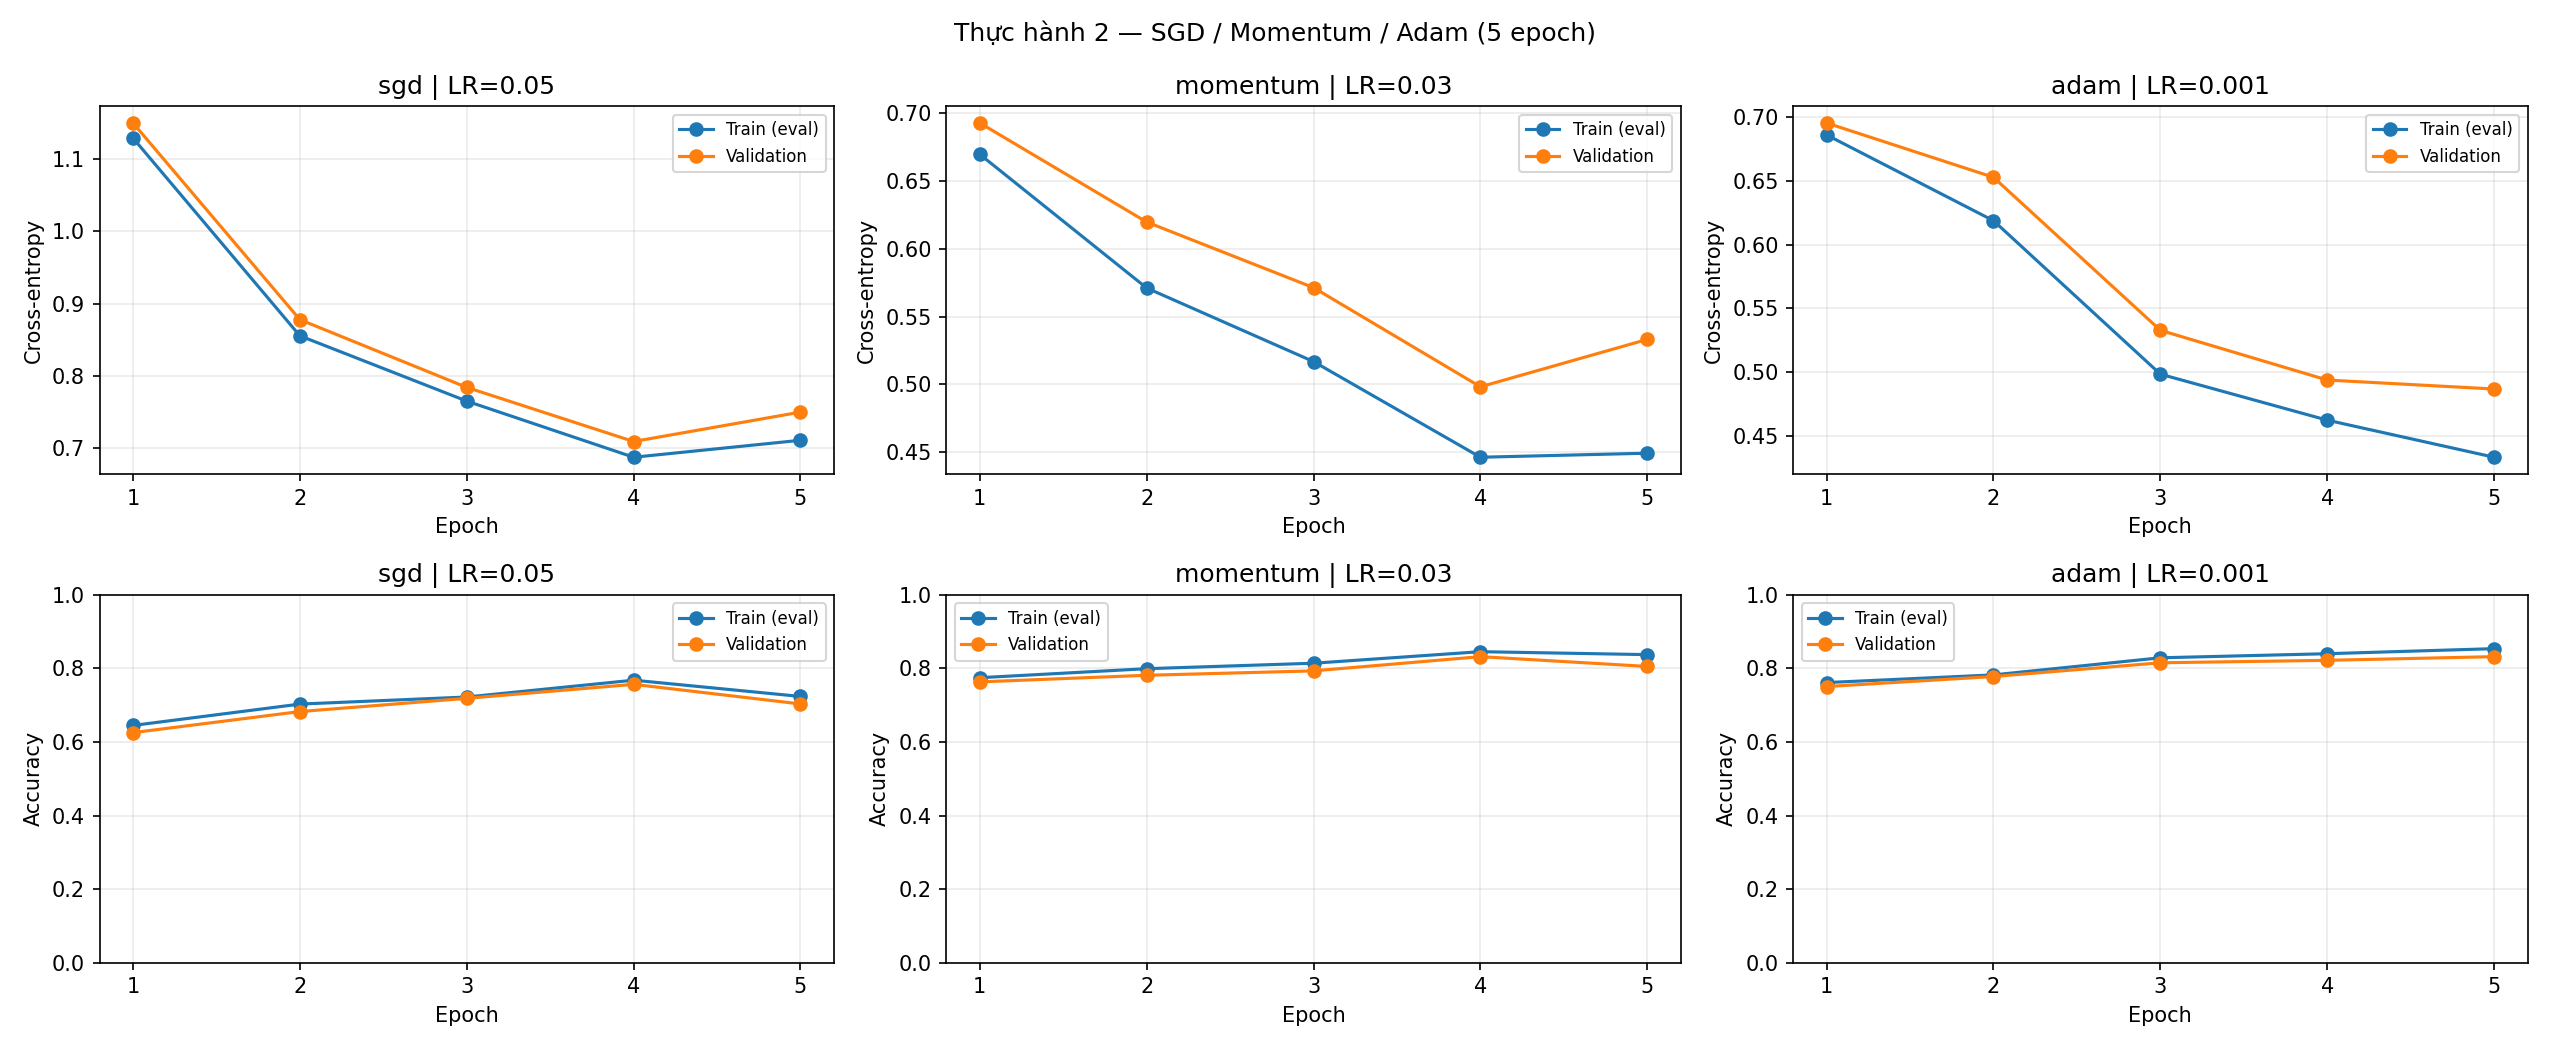

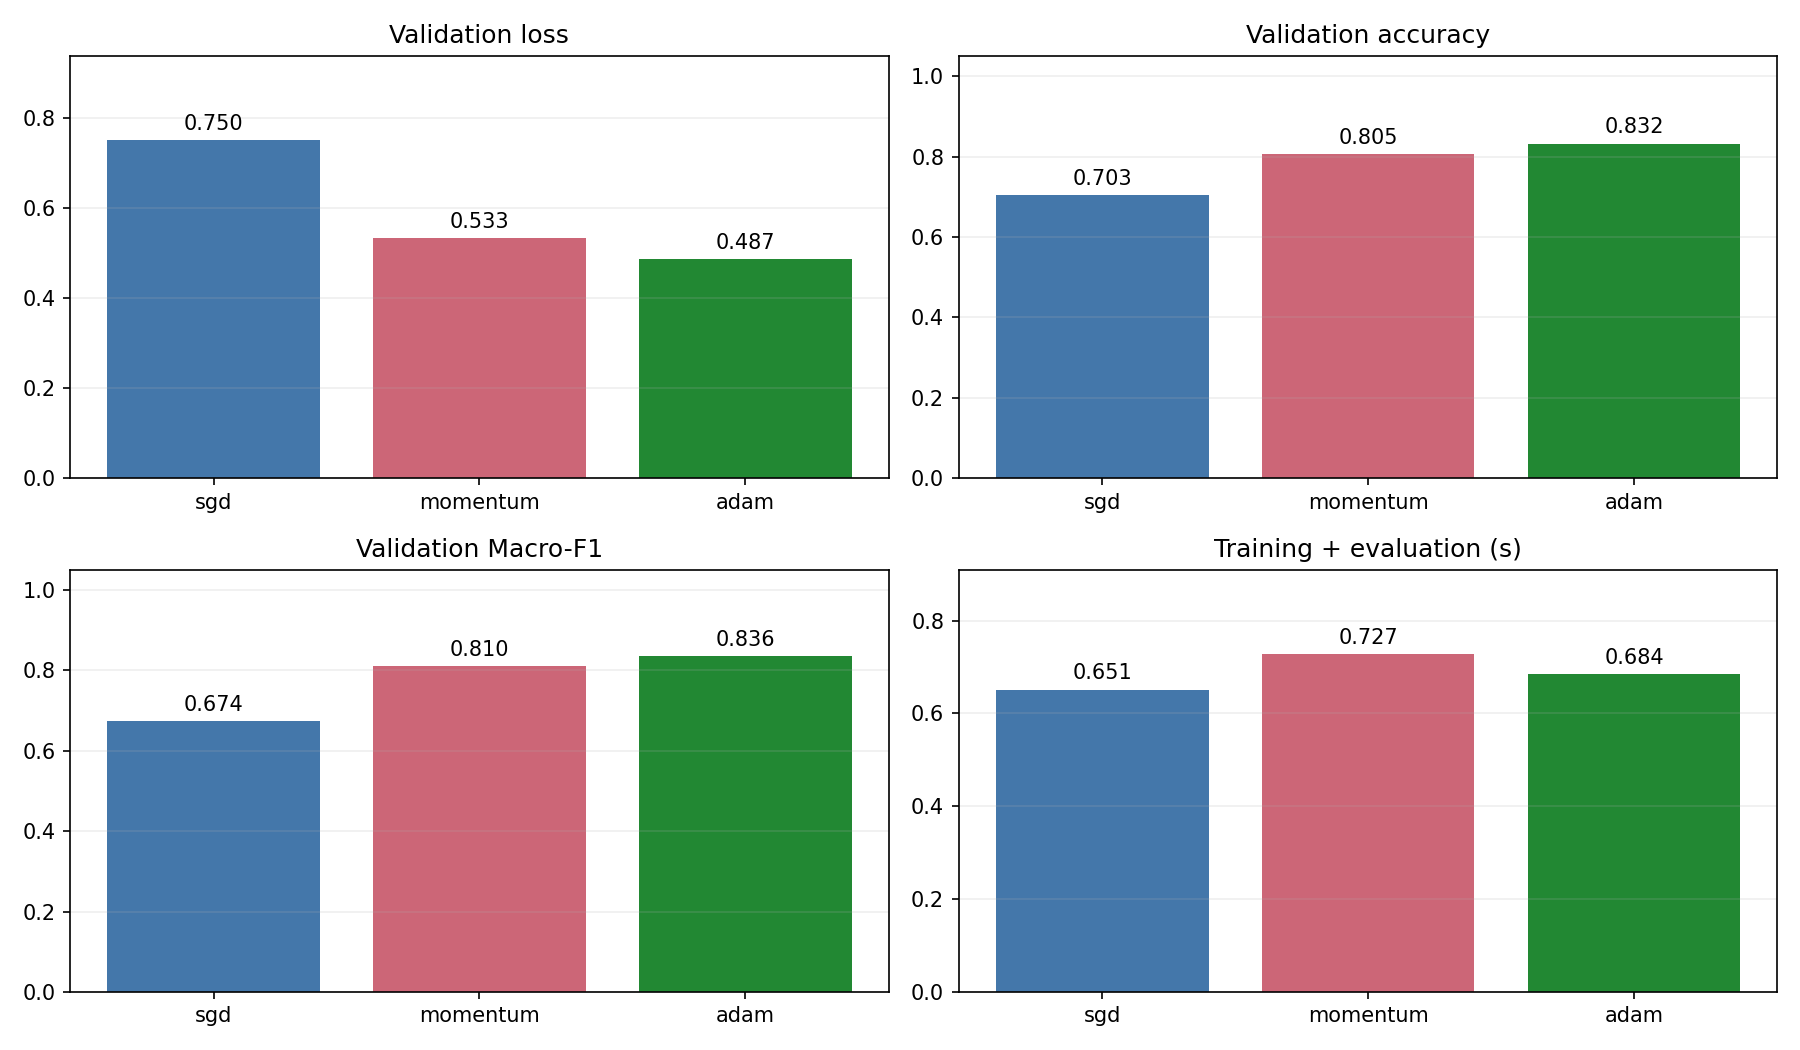

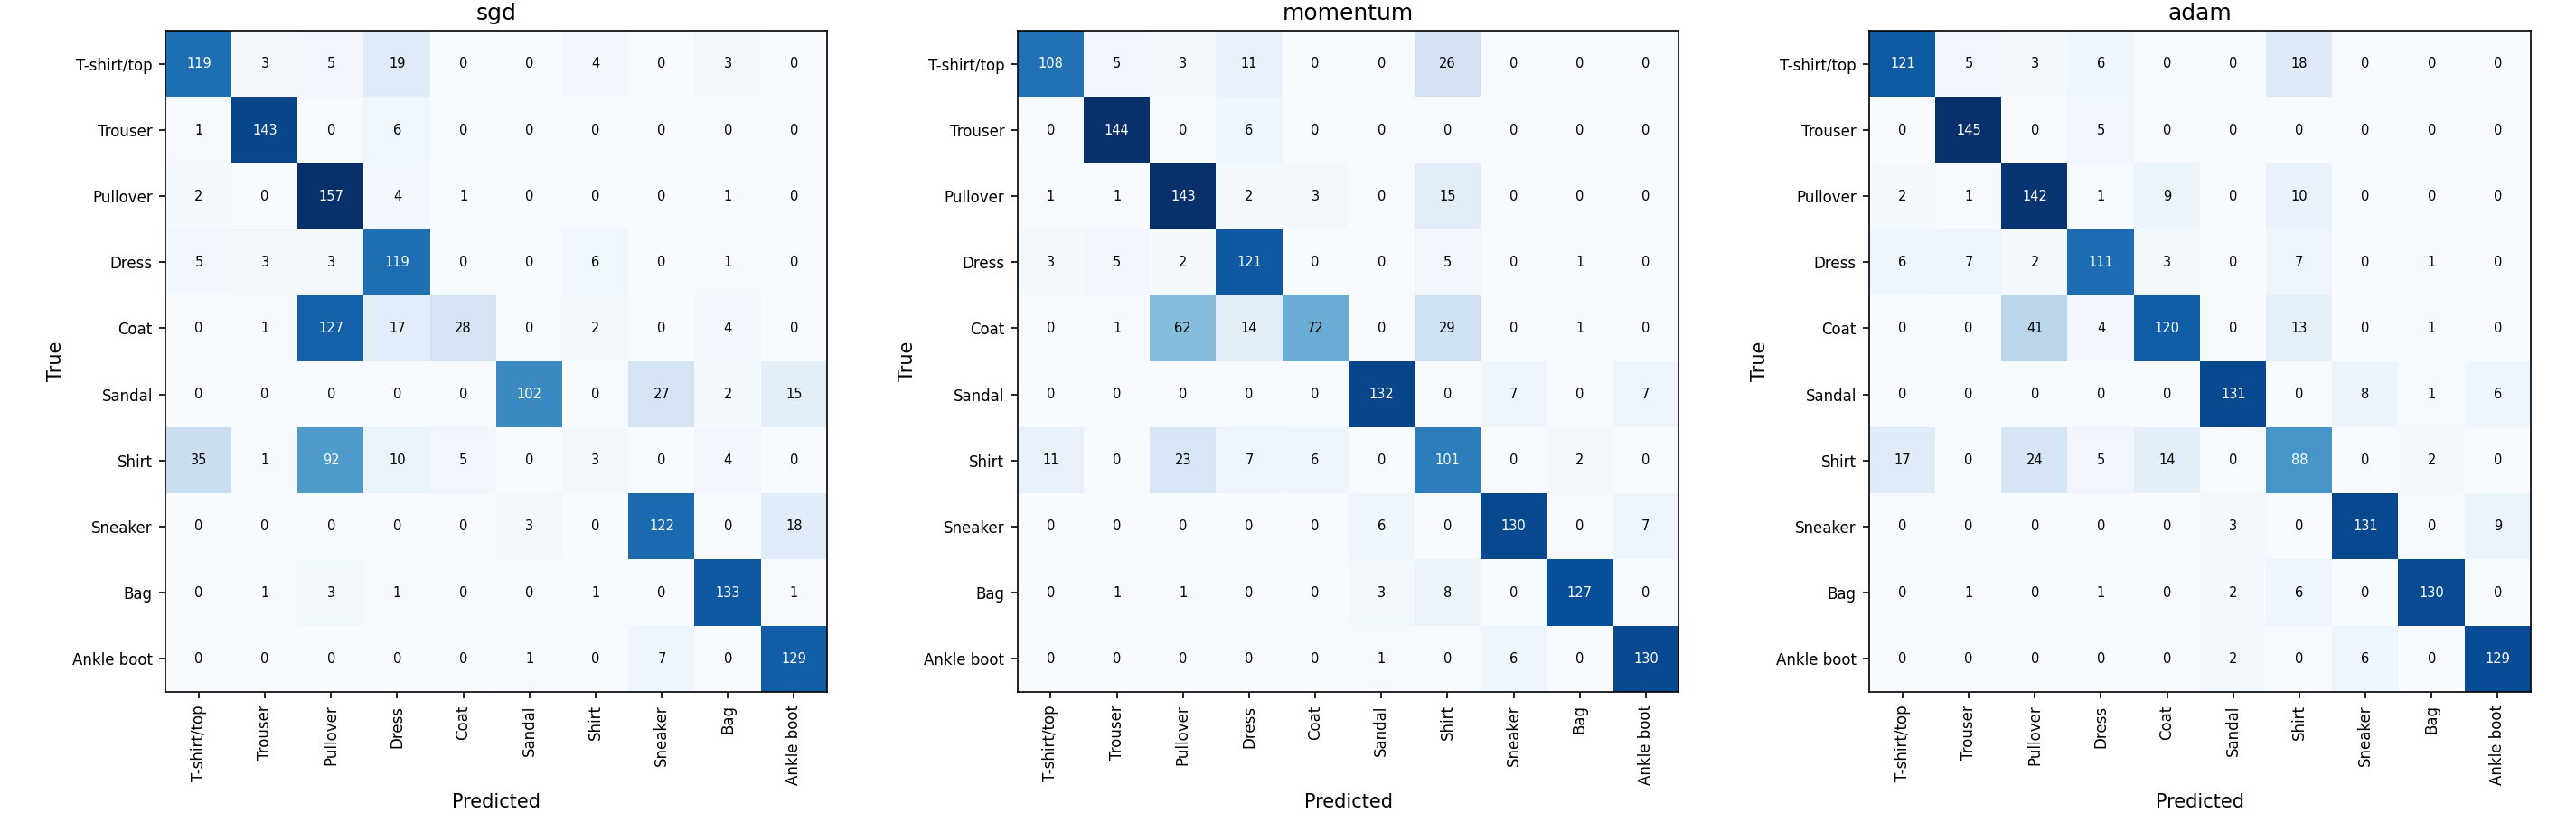

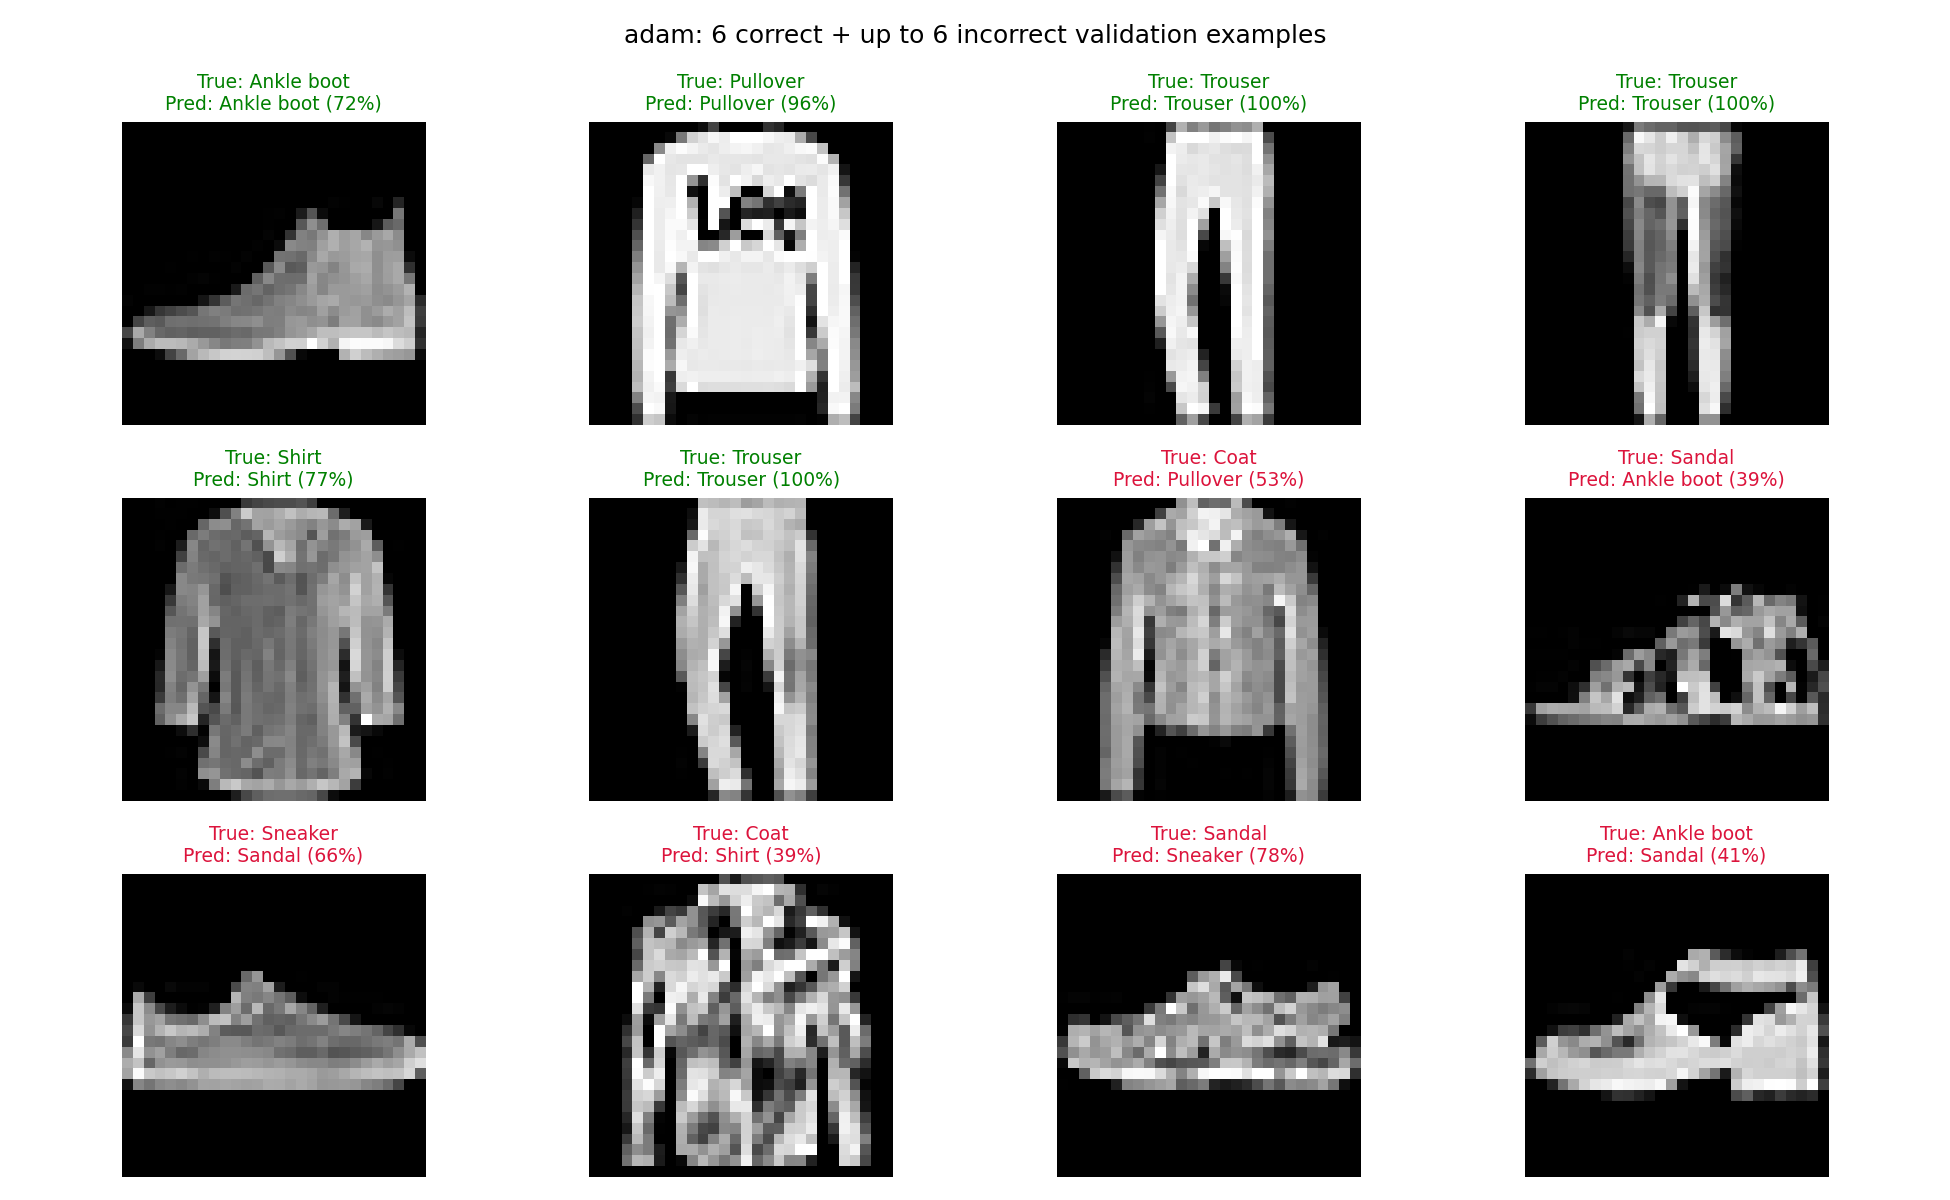

In [6]:
folder = BASE / "results" / "bai2_optimizer"
display(Markdown((folder / "report.md").read_text(encoding="utf-8").split("![")[0]))
for name in ["learning_curves", "comparison", "confusion_matrices", "prediction_examples"]:
    display(Image(filename=str(folder / f"{name}.png")))

# Thực hành 2 — Early Stopping (patience=2, tối đa 5 epoch)

Người làm: **Lê Sơn Trường**.

Fashion-MNIST; train/validation = 8000/1500; MLP 784 → 128 → 10, ReLU; seed42; 5 epoch tối đa. Batch train=128, validation=256; CPU, 2 threads.

Train loss/accuracy trên learning curve được đo lại ở cuối epoch bằng eval, cùng cách với validation. online_train_loss là loss trung bình có trọng số của các batch trong lúc cập nhật; hai đại lượng có thể khác nhau.

| Cấu hình | LR | Momentum | Epoch chạy/chọn | Train loss | Val loss | Val accuracy | Macro-F1 | Giây |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| sgd | 0.05 | 0 | 5/4 | 0.6877 | 0.7095 | 75.67% | 0.7532 | 0.70 |
| momentum | 0.03 | 0.9 | 5/4 | 0.4462 | 0.4982 | 83.20% | 0.8345 | 0.64 |
| adam | 0.001 | 0 | 5/5 | 0.4331 | 0.4867 | 83.20% | 0.8360 | 0.77 |

## Kết quả sau từng epoch

| Cấu hình | Epoch | Device | Số tham số | Train loss | Val loss | Val accuracy |
|---|---:|---|---:|---:|---:|---:|
| sgd | 1 | cpu | 101,770 | 1.1285 | 1.1493 | 62.53% |
| sgd | 2 | cpu | 101,770 | 0.8554 | 0.8777 | 68.27% |
| sgd | 3 | cpu | 101,770 | 0.7652 | 0.7842 | 71.87% |
| sgd | 4 | cpu | 101,770 | 0.6877 | 0.7095 | 75.67% |
| sgd | 5 | cpu | 101,770 | 0.7112 | 0.7501 | 70.33% |
| momentum | 1 | cpu | 101,770 | 0.6697 | 0.6928 | 76.33% |
| momentum | 2 | cpu | 101,770 | 0.5711 | 0.6197 | 78.13% |
| momentum | 3 | cpu | 101,770 | 0.5168 | 0.5713 | 79.33% |
| momentum | 4 | cpu | 101,770 | 0.4462 | 0.4982 | 83.20% |
| momentum | 5 | cpu | 101,770 | 0.4492 | 0.5332 | 80.53% |
| adam | 1 | cpu | 101,770 | 0.6861 | 0.6955 | 75.07% |
| adam | 2 | cpu | 101,770 | 0.6188 | 0.6529 | 77.80% |
| adam | 3 | cpu | 101,770 | 0.4984 | 0.5328 | 81.53% |
| adam | 4 | cpu | 101,770 | 0.4622 | 0.4937 | 82.20% |
| adam | 5 | cpu | 101,770 | 0.4331 | 0.4867 | 83.20% |

## Nhận xét từ kết quả chạy

- **adam** có validation loss thấp nhất: **0.4867**. Accuracy cao nhất thuộc **momentum, adam**: **83.20%**.
- SGD cập nhật trực tiếp theo gradient, ít trạng thái nhưng nhạy với LR; Momentum tích lũy hướng cập nhật, có thể giảm dao động; Adam dùng trung bình gradient và bình phương gradient để điều chỉnh bước cho từng tham số.
- LR của ba optimizer khác nhau đúng theo mã mẫu (.05/.03/.001). Đây là so sánh ba cấu hình được giao, chưa tách riêng ảnh hưởng của optimizer và chưa tìm siêu tham số tốt nhất cho từng thuật toán.
- sgd, epoch 4 → 5: train loss 0.6877 → 0.7112 và val loss 0.7095 → 0.7501 cùng tăng. Đây có thể là dao động cập nhật do LR/mini-batch; chưa đủ để kết luận overfitting. Có thể thử giảm LR trong khảo sát riêng, giữ bảng chính đúng cấu hình đề.
- momentum, epoch 4 → 5: train loss 0.4462 → 0.4492 và val loss 0.4982 → 0.5332 cùng tăng. Đây có thể là dao động cập nhật do LR/mini-batch; chưa đủ để kết luận overfitting. Có thể thử giảm LR trong khảo sát riêng, giữ bảng chính đúng cấu hình đề.
- Early Stopping: patience=2, min_delta=0; theo dõi validation loss, khôi phục trọng số tốt nhất. Ngân sách vẫn tối đa 5 epoch như đề.
- Lần chạy này chưa cấu hình nào dừng trước 5 epoch. Cài đặt không bảo đảm sẽ dừng nếu loss còn cải thiện.
- Tất cả cấu hình trong mỗi bài dùng cùng trọng số khởi tạo và cùng thứ tự mini-batch. Số tham số gồm weight và bias; thời gian gồm huấn luyện và đánh giá mỗi epoch, không gồm đọc dữ liệu, khởi tạo hay vẽ biểu đồ.
- Giữ split của mã gốc: validation lấy từ test chính thức. Sau khi dùng để so sánh LR/optimizer, không xem đây là điểm test độc lập. Chỉ một seed và 5 epoch nên kết luận có phạm vi giới hạn.
- Nếu loss không giảm: kiểm tra chuẩn hóa /255, nhãn long, logits thô cho CE, zero_grad/backward/step và LR. Nếu train tốt nhưng val kém: cân nhắc giảm capacity, regularization hoặc thêm dữ liệu trong thí nghiệm mở rộng có ghi rõ cấu hình.



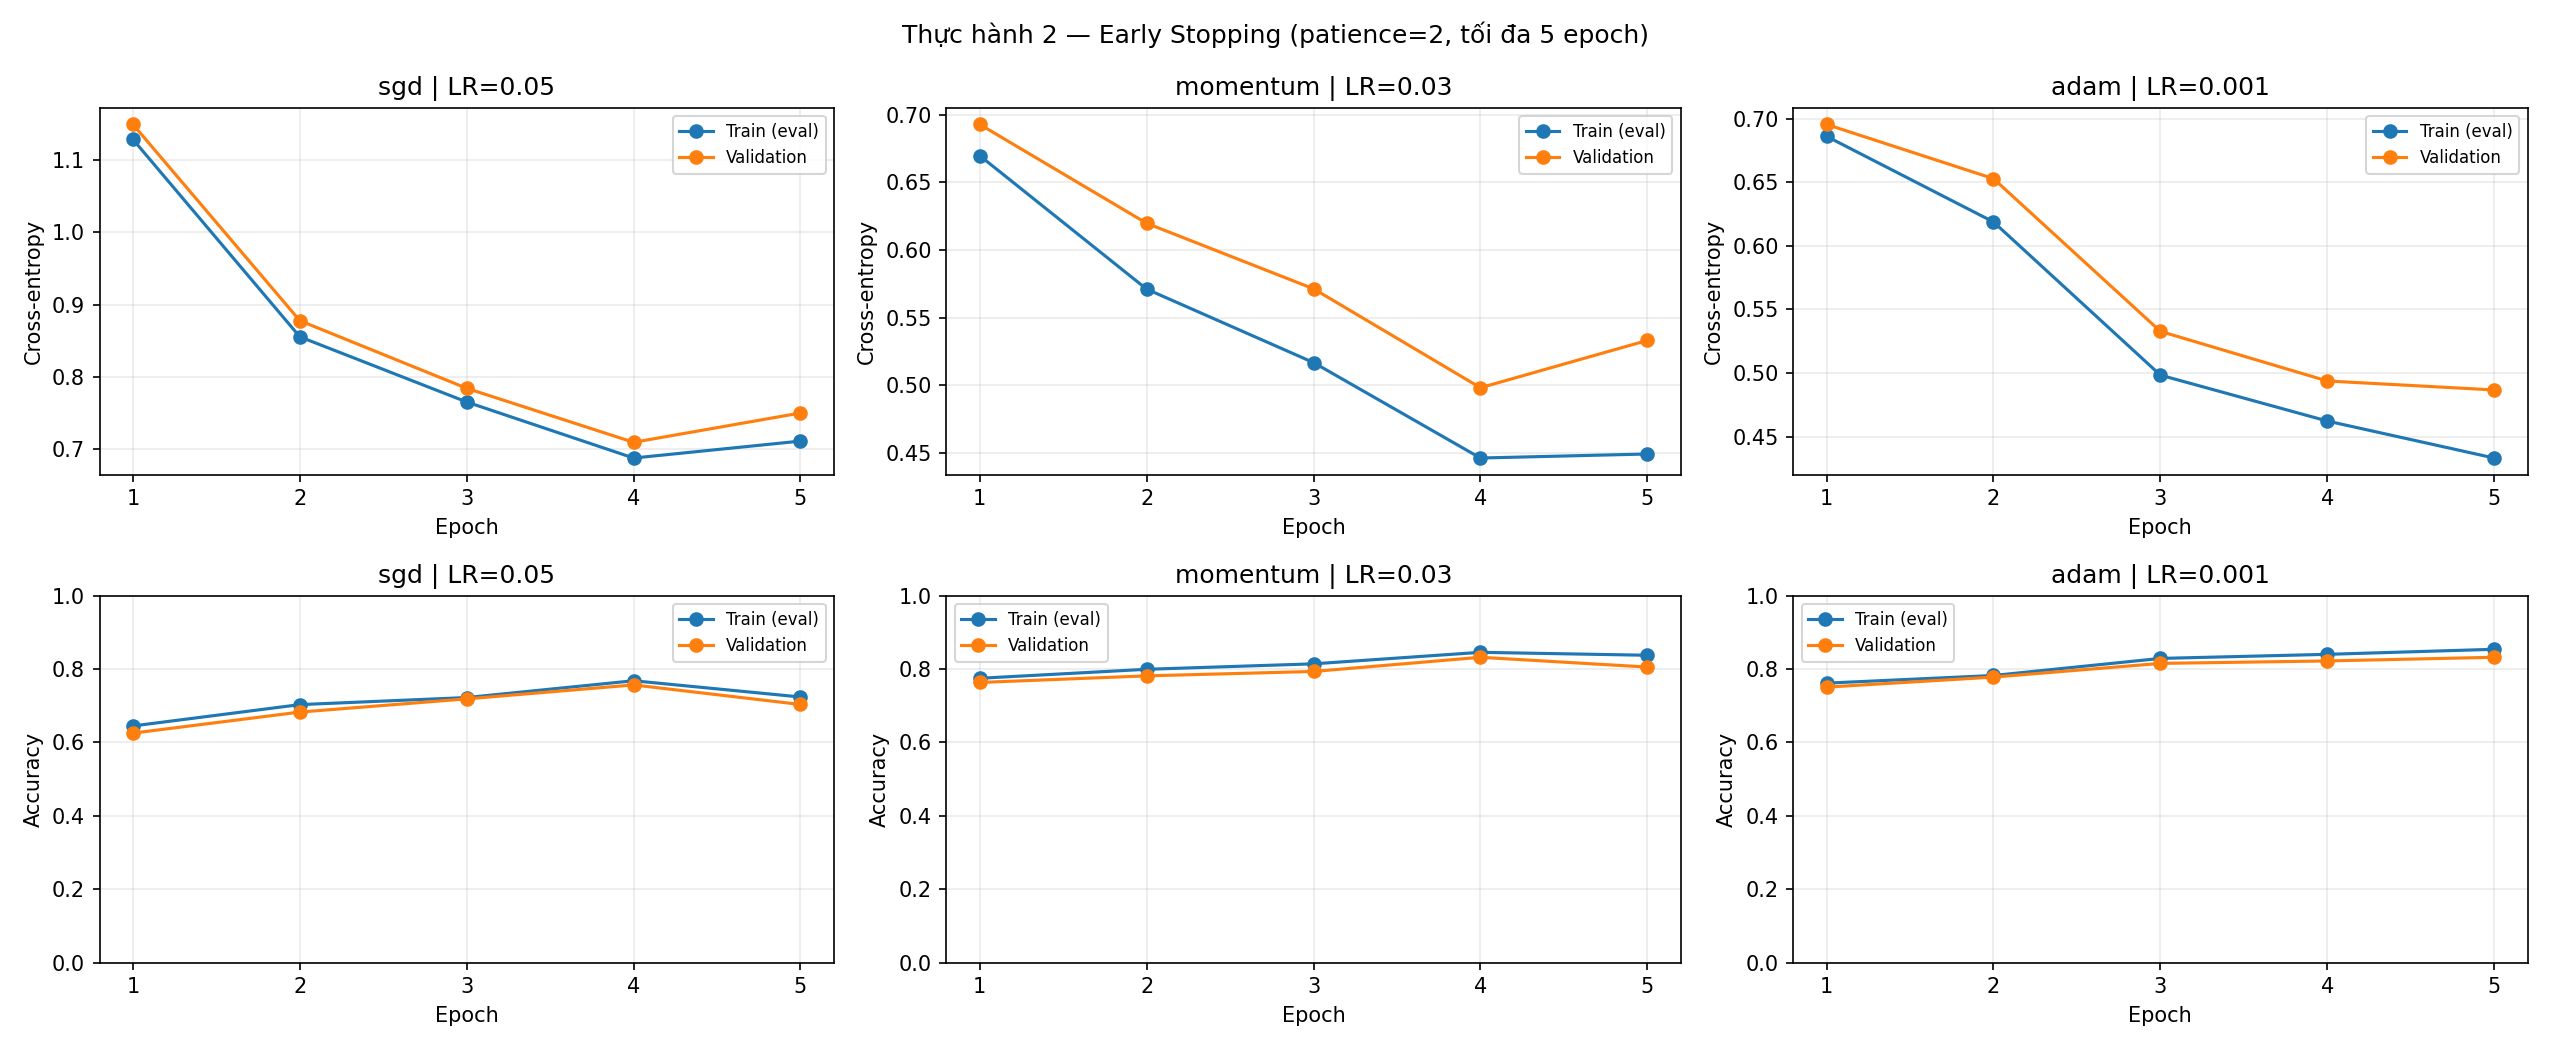

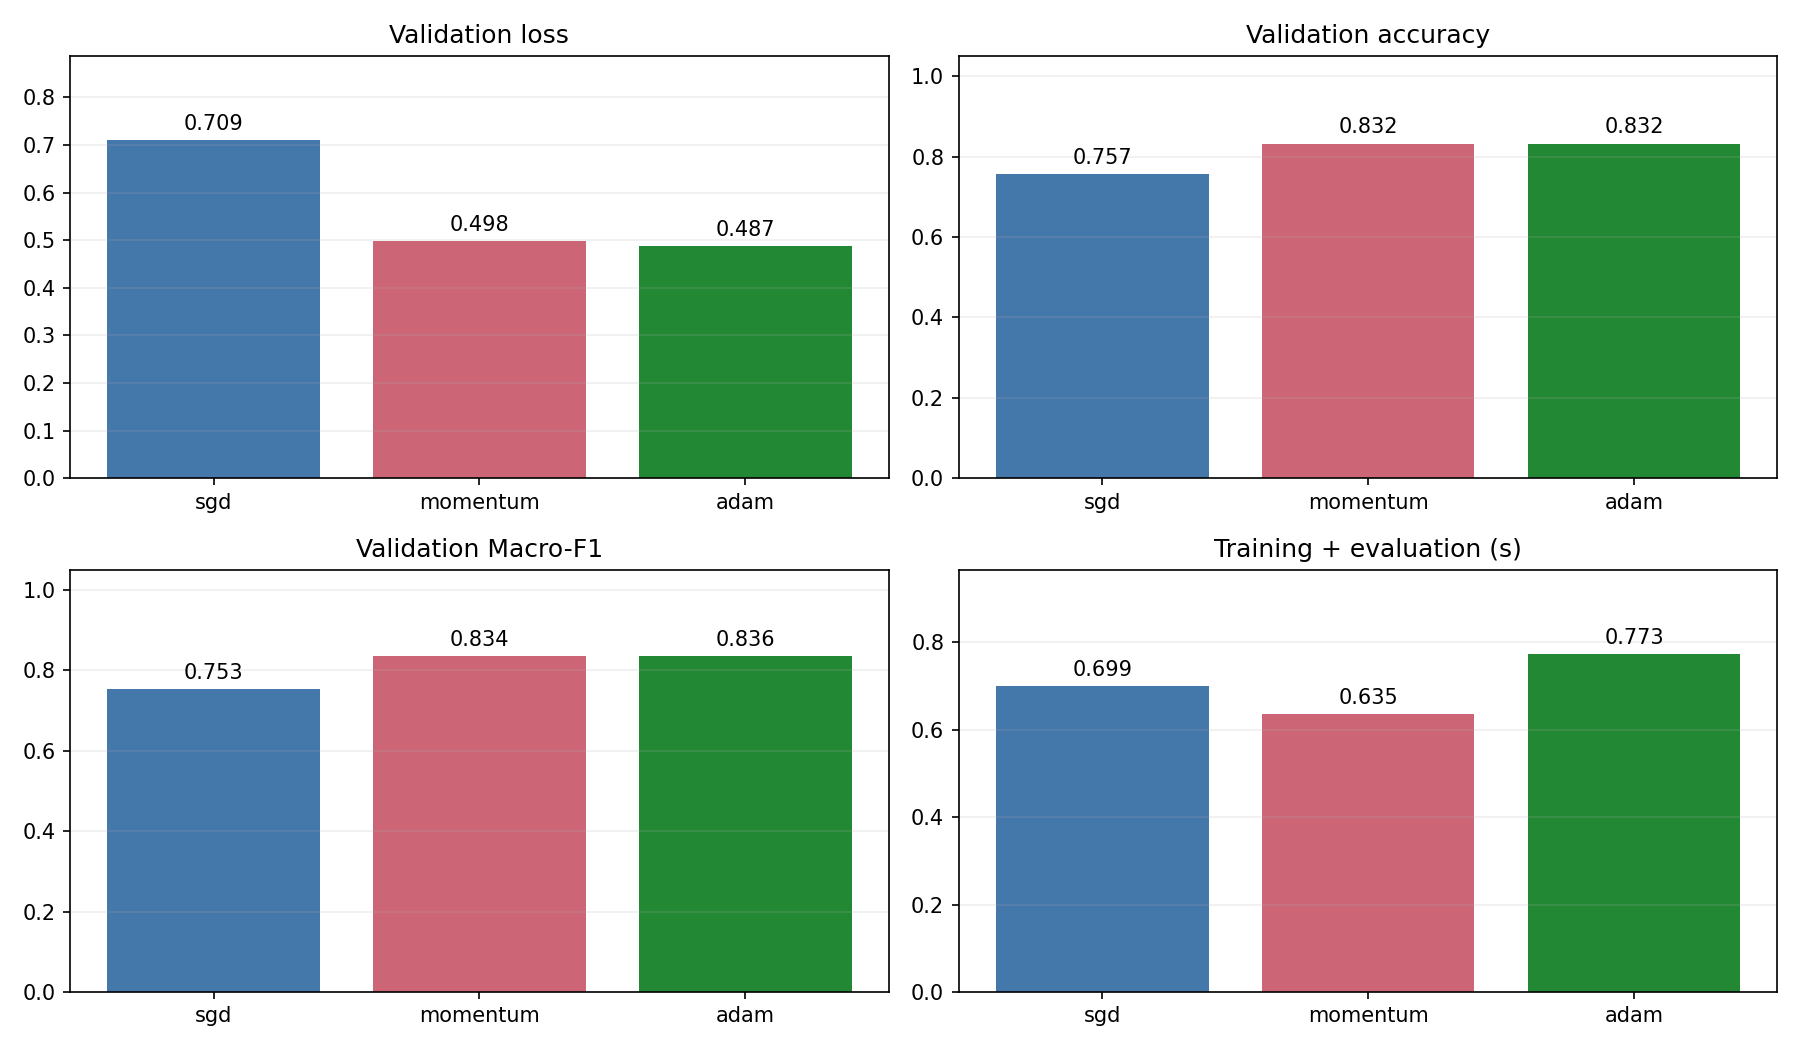

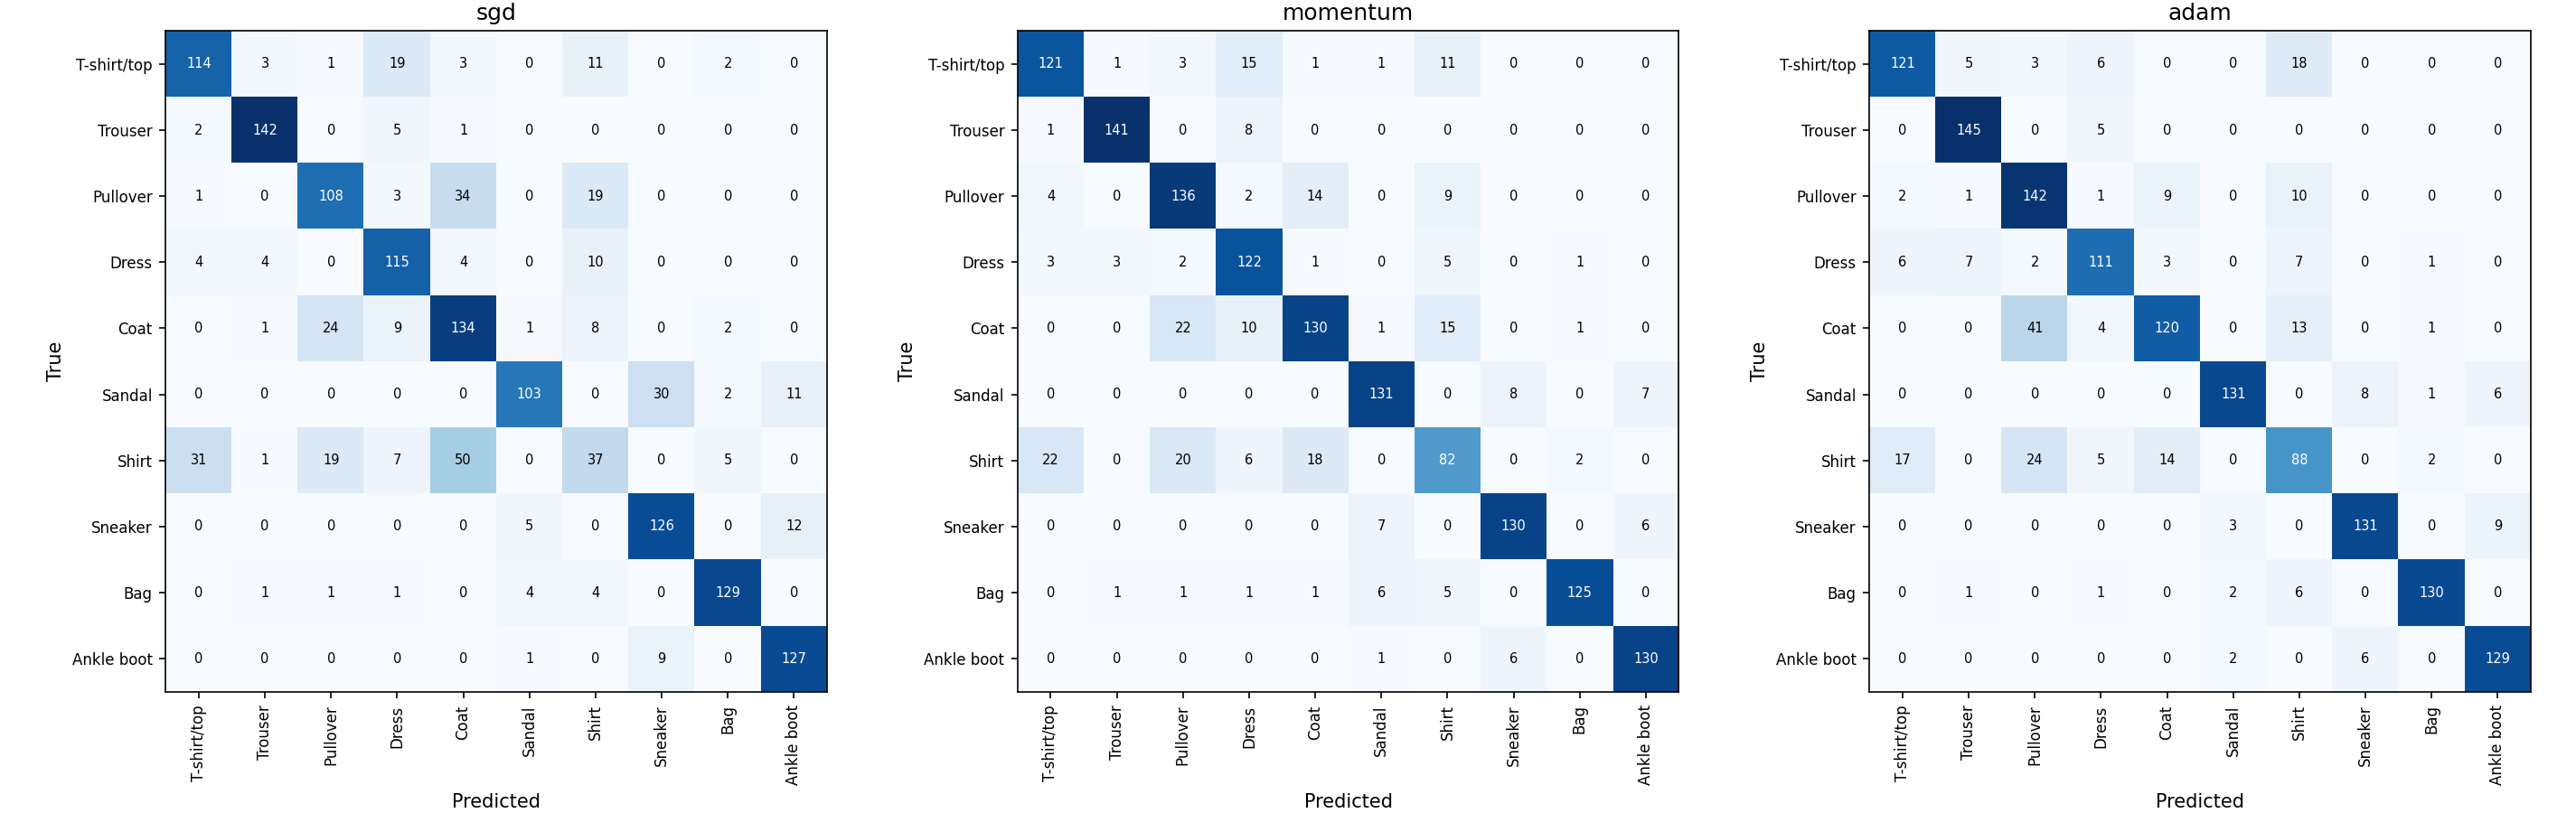

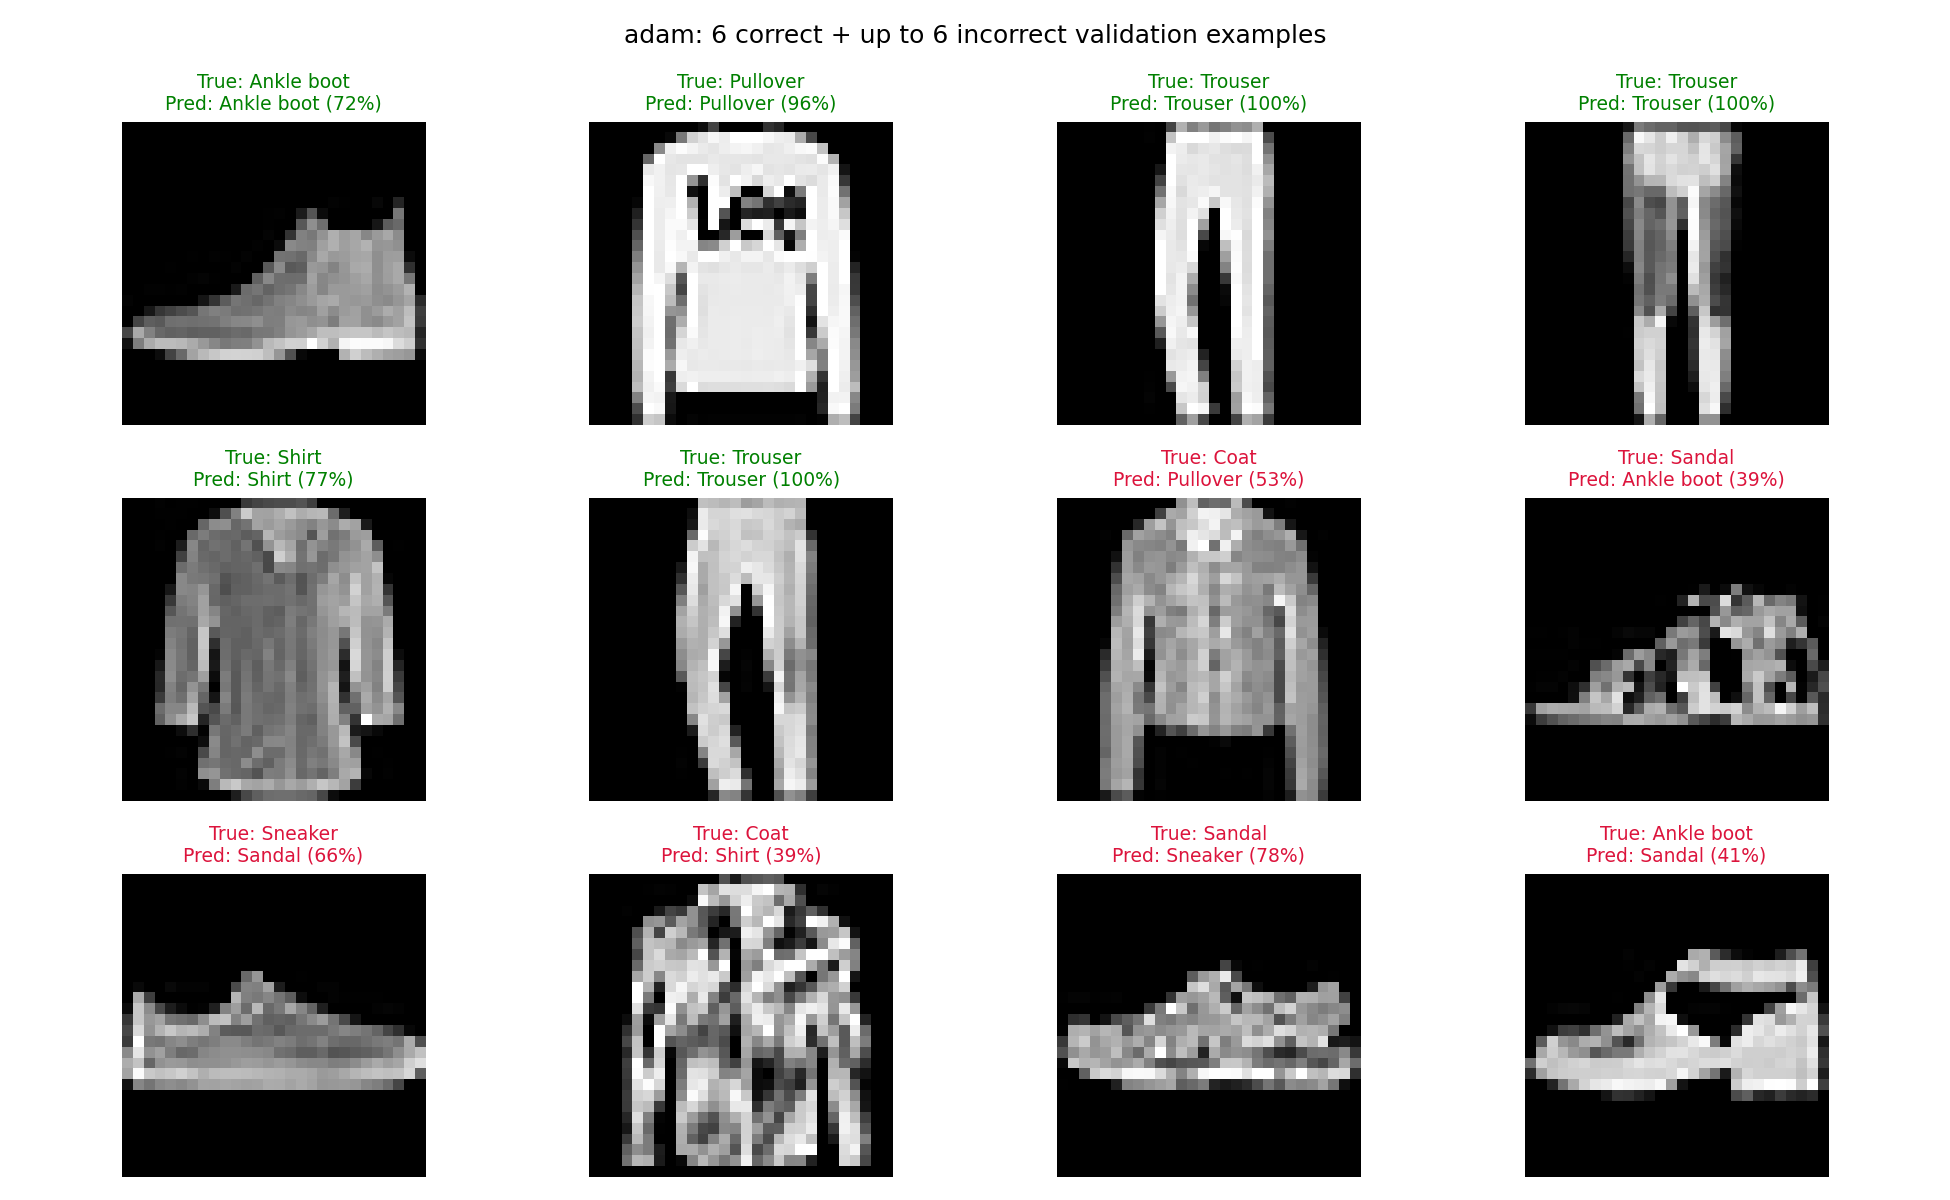

In [7]:
folder = BASE / "results" / "bai2_early_stopping"
display(Markdown((folder / "report.md").read_text(encoding="utf-8").split("![")[0]))
for name in ["learning_curves", "comparison", "confusion_matrices", "prediction_examples"]:
    display(Image(filename=str(folder / f"{name}.png")))